# ⏱️ Notebook 6 — Dynamic Monte Carlo: Gillespie's Method
| | |
|---|---|
| ⏱ Time | ~45 min |
| 🧭 Type | **dynamic Monte Carlo** (book Ch. 4) |
| 🎯 You will learn | Gillespie's method · macroscopic → microscopic rate constants · control volume · a batch **free-radical polymerization** in time |
| 🧰 Uses | Trick #3 (roulette wheel) + Trick #4 (waiting time) from Notebook 1 |
| 📖 Book | Sec. 4.5, Table 4.1, Algorithm 4.3 *Generic Gillespie Algorithm for Free Radical Polymerization* |

Notebooks 2–4 were **steady state** models: constant probabilities, no time. In a batch reactor, monomer and initiator are used up, so the rates keep changing. **Dynamic Monte Carlo** follows every reaction event on a clock. Details: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

random.seed(2)
NA = 6.022e23

## 1 · Gillespie's method in five lines
```
loop:
    compute the propensity R_j of every reaction channel
    pick reaction j with the roulette wheel           (Trick #3)
    execute it (update the molecule counts)
    advance the clock: t ← t + ln(1/Rnd) / R_total    (Trick #4)
```
### Warm-up: a single reaction, A → B
One reaction channel with propensity `R = k · n_A`. Each event turns one A into B.

In [2]:
def decay(nA0, k):
    nA, t = nA0, 0.0
    times, counts = [0.0], [nA0]
    while nA > 0:
        R = k * nA                                  # propensity
        t += np.log(1 / random.random()) / R        # when?
        nA -= 1                                     # what: A → B
        times.append(t)
        counts.append(nA)
    return np.array(times), np.array(counts)

In [3]:
decay_runs = {}
for nA0 in [20, 200, 5000]:
    decay_runs[nA0] = decay(nA0, k=0.1)

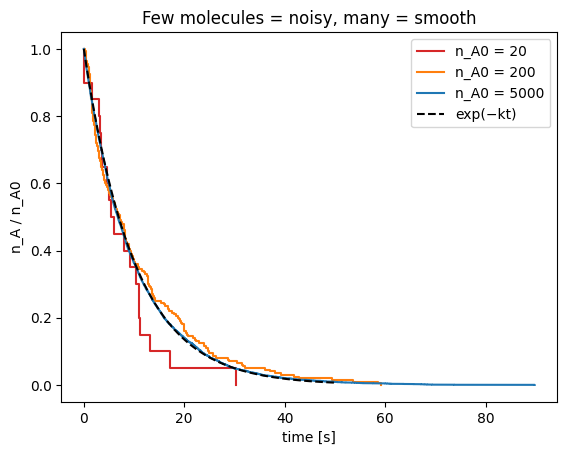

In [4]:
#@title Plot the decay against exp(−kt)
for nA0, c in [(20, "tab:red"), (200, "tab:orange"), (5000, "tab:blue")]:
    t, nA = decay_runs[nA0]; plt.step(t, nA/nA0, c=c, where="post", label=f"n_A0 = {nA0}")
tt = np.linspace(0, 50, 100); plt.plot(tt, np.exp(-0.1*tt), "k--", label="exp(−kt)")
plt.xlabel("time [s]"); plt.ylabel("n_A / n_A0"); plt.legend(); plt.title("Few molecules = noisy, many = smooth"); plt.show()

## 2 · Macroscopic → microscopic rate constants (book Table 4.1)
We simulate a small **control volume** `V`. Concentrations become molecule counts, `n = [C]·N_A·V`, and each rate constant gets a Monte Carlo version:

| Reaction | Propensity | Microscopic rate constant |
|---|---|---|
| initiator decomposition, `I → 2R` | `k_d^MC · n_I` | `k_d^MC = k_d` |
| initiation, `R + M → P₁` | `k_i^MC · n_M · n_R` | `k_i / (V·N_A)` |
| propagation, `Pₙ + M → Pₙ₊₁` | `k_p^MC · n_M · n_P` | `k_p / (V·N_A)` |
| transfer to monomer, `Pₙ + M → Dₙ + P₁` | `k_tM^MC · n_M · n_P` | `k_tM / (V·N_A)` |
| combination, `Pₙ + Pₘ → Dₙ₊ₘ` | `k_tc^MC · n_P(n_P − 1) / 4` | `2k_tc / (V·N_A)` |

⚠️ **Illustrative parameters.** With realistic rate constants, the control volume needs ~10⁹–10¹⁰ monomer molecules to hold even a few polymer radicals (book Sec. 4.6, reproduced in Notebook 10). So that this runs in seconds, we use illustrative rate constants with 500,000 monomer molecules and about 100 polymer radicals.

In [5]:
M0, I0 = 1.0, 0.04          # mol/L
f, kd = 0.5, 0.02           # initiator efficiency, 1/s
ki = kp = 400.0             # L/(mol·s)
ktM = 0.4                   # transfer to monomer, L/(mol·s)
ktc = 2e4                   # combination, L/(mol·s)

Choose the control volume from the number of monomer molecules we want, then convert every rate constant (Table 4.1):

In [6]:
nM0 = 500_000
VNA = nM0 / M0              # V·N_A, in L/mol
nI0 = round(I0 * VNA)

kd_MC, ki_MC, kp_MC = kd, ki / VNA, kp / VNA
ktM_MC, ktc_MC = ktM / VNA, 2 * ktc / VNA

The book's rule: the control volume must hold well over one polymer radical. A quick estimate:

In [7]:
P_expected = np.sqrt(2 * f * kd * I0 / ktc)      # mol/L
print(f"n_I0 = {nI0:,}")
print(f"expected polymer radicals: {P_expected * VNA:.0f}")

n_I0 = 20,000
expected polymer radicals: 100


## 3 · The state of the reactor
Everything the simulation needs to remember, in one dictionary:
- `nI`, `nR`, `nM`: initiator, primary radicals, monomer
- `P`: a list with the length of every polymer radical (living chain)
- `dead`: a list with the length of every dead chain

In [8]:
def new_reactor():
    return {"nI": nI0, "nR": 0, "nM": nM0, "P": [], "dead": []}

## 4 · One small function per reaction
Each function changes the state exactly as its chemical equation says. Picking a random polymer radical = picking a random position in `P`.

In [9]:
def decomposition(s):                 # I → 2R  (efficiency f)
    s["nI"] -= 1
    if random.random() <= f:
        s["nR"] += 2

In [10]:
def initiation(s):                    # R + M → P1
    s["nR"] -= 1
    s["nM"] -= 1
    s["P"].append(1)

In [11]:
def propagation(s):                   # Pn + M → Pn+1
    k = random.randrange(len(s["P"]))
    s["P"][k] += 1
    s["nM"] -= 1

In [12]:
def transfer(s):                      # Pn + M → Dn + P1
    k = random.randrange(len(s["P"]))
    s["dead"].append(s["P"][k])
    s["P"][k] = 1
    s["nM"] -= 1

Combination removes two radicals. We reuse the pool trick (Notebook 4) to take a random radical out of `P`:

In [13]:
def take_random(pool):
    k = random.randrange(len(pool))
    chosen = pool[k]
    pool[k] = pool[-1]
    pool.pop()
    return chosen

In [14]:
def combination(s):                   # Pn + Pm → Dn+m
    n = take_random(s["P"])
    m = take_random(s["P"])
    s["dead"].append(n + m)

Keep the reactions in a list. Their order must match the order of the propensities below.

In [15]:
REACTIONS = [decomposition, initiation, propagation, transfer, combination]
NAMES = ["initiator decomposition", "chain initiation", "propagation",
         "transfer to monomer", "combination"]

## 5 · Propensities (Table 4.1)

In [16]:
def propensities(s):
    nP = len(s["P"])
    return [kd_MC * s["nI"],
            ki_MC * s["nR"] * s["nM"],
            kp_MC * nP * s["nM"],
            ktM_MC * nP * s["nM"],
            ktc_MC * nP * (nP - 1) / 4]

And the roulette wheel from Notebook 1:

In [17]:
def pick_event(rates):
    r = random.random() * sum(rates)
    cumulative = 0
    for j in range(len(rates)):
        cumulative += rates[j]
        if r <= cumulative:
            return j

## 6 · The Gillespie loop
Now the five-line recipe from section 1 becomes real code. Let's watch the first 12 events (the book calls this an **event log**):

In [18]:
s = new_reactor()
t = 0.0

for event in range(12):
    R = propensities(s)
    j = pick_event(R)
    REACTIONS[j](s)
    t += np.log(1 / random.random()) / sum(R)
    print(f"t = {t:.4f} s  {NAMES[j]:<24} n_I = {s['nI']:,}  n_R = {s['nR']}  n_P = {len(s['P'])}")

t = 0.0014 s  initiator decomposition  n_I = 19,999  n_R = 2  n_P = 0
t = 0.0031 s  initiator decomposition  n_I = 19,998  n_R = 2  n_P = 0
t = 0.0032 s  initiator decomposition  n_I = 19,997  n_R = 2  n_P = 0
t = 0.0038 s  initiator decomposition  n_I = 19,996  n_R = 2  n_P = 0
t = 0.0039 s  chain initiation         n_I = 19,996  n_R = 1  n_P = 1
t = 0.0040 s  initiator decomposition  n_I = 19,995  n_R = 3  n_P = 1
t = 0.0045 s  initiator decomposition  n_I = 19,994  n_R = 3  n_P = 1
t = 0.0049 s  initiator decomposition  n_I = 19,993  n_R = 5  n_P = 1
t = 0.0057 s  chain initiation         n_I = 19,993  n_R = 4  n_P = 2
t = 0.0058 s  chain initiation         n_I = 19,993  n_R = 3  n_P = 3
t = 0.0059 s  initiator decomposition  n_I = 19,992  n_R = 5  n_P = 3
t = 0.0062 s  propagation              n_I = 19,992  n_R = 5  n_P = 3


Initiator decomposition must happen before anything else can. Now run the whole batch until 95 % conversion. Every 2,000 events we write down the time, conversion and number of radicals.

In [19]:
s = new_reactor()
t, step = 0.0, 0
history = {"t": [], "x": [], "nP": []}

while (nM0 - s["nM"]) / nM0 < 0.95:
    R = propensities(s)
    j = pick_event(R)
    REACTIONS[j](s)
    t += np.log(1 / random.random()) / sum(R)
    step += 1
    if step % 2000 == 0:
        history["t"].append(t)
        history["x"].append((nM0 - s["nM"]) / nM0)
        history["nP"].append(len(s["P"]))

In [20]:
print(f"{step:,} events,  final time {t:.1f} s,  {len(s['dead']):,} dead chains")

492,505 events,  final time 44.0 s,  6,250 dead chains


## 7 · ✅ Validation against the deterministic (ODE) model
With enough molecules, the average Monte Carlo behaviour must match the rate equations written with the same conventions (combination removes radicals at the rate `k_tc[P]²`). The ODE solution is in the collapsed cell.

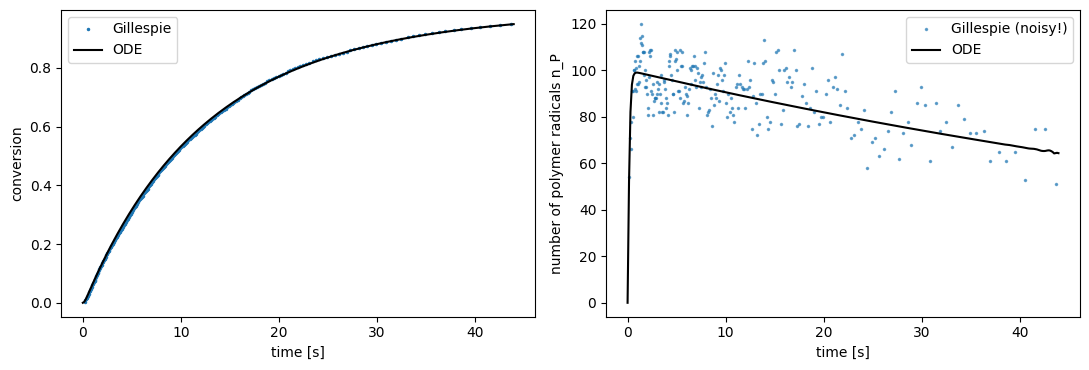

In [21]:
#@title Solve the ODEs and plot both
def odes(time, y):
    I, Rr, P, M = y
    return [-kd*I, 2*f*kd*I - ki*Rr*M, ki*Rr*M - ktc*P**2, -ki*Rr*M - (kp + ktM)*P*M]
sol = solve_ivp(odes, [0, t], [I0, 0, 0, M0], method="LSODA", dense_output=True, rtol=1e-8)
tt = np.linspace(0, t, 300); I, Rr, Pr, M = sol.sol(tt)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history["t"], history["x"], ".", ms=3, label="Gillespie"); ax[0].plot(tt, 1 - M/M0, "k-", label="ODE")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("conversion"); ax[0].legend()
ax[1].plot(history["t"], history["nP"], ".", ms=3, alpha=0.6, label="Gillespie (noisy!)"); ax[1].plot(tt, Pr*VNA, "k-", label="ODE")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("number of polymer radicals n_P"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8 · What the ODE can't easily give you: the full MWD
Monte Carlo keeps every dead chain, so the whole distribution is right there:

In [22]:
dead = np.array(s["dead"])
Nn = dead.mean()
Nw = np.sum(dead**2) / np.sum(dead)
print(f"Nn = {Nn:.0f}   Nw = {Nw:.0f}   Đ = {Nw / Nn:.2f}")

Nn = 76   Nw = 156   Đ = 2.06


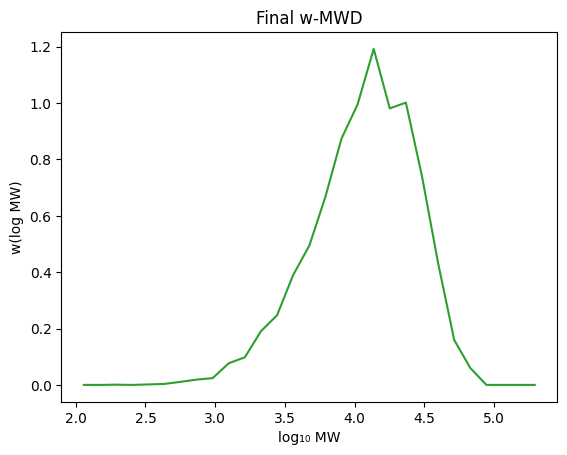

In [23]:
#@title Plot the final w-MWD
edges = np.logspace(0, np.log10(3*dead.max()), 30)
h, _ = np.histogram(dead, bins=edges, weights=dead)
x = np.log10(np.sqrt(edges[1:]*edges[:-1]) * 100.12); y = h/np.diff(np.log10(edges)); y /= np.trapezoid(y, x)
plt.plot(x, y, c="tab:green"); plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.title("Final w-MWD"); plt.show()

## ✅ Recap
- Gillespie's method = **propensities → roulette wheel → execute → advance the clock**.
- One small function per reaction keeps the code identical to the chemical equations.
- Bimolecular rate constants are divided by `V·N_A`; combination needs the extra factors of Table 4.1.
- The **control volume** must hold enough polymer radicals (Notebook 10).

### 🧪 Try it yourself
1. Set `ktM = 0` and re-run from section 2. What happens to Đ?
2. Raise `ktM` ten-fold. Which changes: conversion, Nn, or both?
3. Set `nM0 = 5_000`. How many radicals are in the control volume now, and what happens to the results?

➡️ **Next: Notebook 7 — Dynamic Monte Carlo: ATRP & polymer degradation**